In [1]:
from microtorch.model_maker import ModelMaker
from microtool.microtorch import MicrotorchTissueModel
from microtool.tissue_model import MultiTissueModel, RelaxationTissueModel
from microtool.utils.unit_registry import unit

microtorch_model = ModelMaker("Ball")





# Wrap each compartment individually, not the combined ModelMaker model.

ball_model = MicrotorchTissueModel(
    microtorch_model,
    parameters={"D": 2},
)



ball_relax = RelaxationTissueModel(ball_model, t2=50e-3 * unit("s"))


ball_model = ball_relax
ball_model["model_D"].optimize = True
ball_model["model_D"].fit_flag = True
ball_model["model_D"].scale = 1
#ball_model["model_D"].value_list = [1.8, 2, 2.2]

ball_model["S0"].optimize = True
ball_model["S0"].fit_flag = True
ball_model["S0"].scale = 1

ball_model["T2"].optimize = True
ball_model["T2"].fit_flag = True
ball_model["T2"].scale = 1
#ball_model["T2"].value_list = [0.04, 0.05, 0.06]

print(ball_model)

print(type(ball_model._model))
print(type(ball_model._model).scaled_jacobian.__qualname__)

No YAML configuration found for Ball model.
Falling back to parsing model name for compartments: ['Ball'].
Parameter ranges will be the default compartment values.
-----------
########### Making model:  Ball
########### Compartments: ['Ball']
########### Parameter names: [['D']]
########### Parameter ranges: [[[0.001, 3]]]
-----------
Tissue model with 3 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  -------------
model_D                2           1  True        True   (0.001, 3.0)
T2                     0.05        1  True        True   (0.0001, 1.0)
S0                     1           1  True        True   (0.0, 2.0)
<class 'microtool.microtorch.MicrotorchTissueModel'>
MicrotorchTissueModel.scaled_jacobian


In [2]:
import numpy as np
from microtool.acquisition_scheme import DiffusionAcquisitionScheme
from microtool.gradient_sampling import sample_uniform_half_sphere

n_directions = 6
n_shells = 3
block_size = n_directions + 1  # b0 + n_directions

shell_bvals = [200, 354, 500, 500, 800, 900]
shell_deltas = [0.0114, 0.0105, 0.02, 0.02, 0.02, .02]
shell_Deltas = [0.0222, 0.0212, 0.03, 0.03, 0.03, 0.03]
initial_te = [0.09, 0.04, 0.06, 0.06, 0.07, 0.09]

# Build the measurements in shell blocks: b0, then six directions.
b_vals_list = []
pulse_durations_list = []
pulse_intervals_list = []
echo_times_list = []

for i in range(n_shells):
    b_vals_list.append(0.0)
    b_vals_list.extend([shell_bvals[i]] * n_directions)

    pulse_durations_list.extend([shell_deltas[i]] * block_size)
    pulse_intervals_list.extend([shell_Deltas[i]] * block_size)
    echo_times_list.extend([initial_te[i]] * block_size)

b_vals = np.array(b_vals_list)
pulse_durations = np.array(pulse_durations_list)
pulse_intervals = np.array(pulse_intervals_list)
echo_times = np.array(echo_times_list)
directions = sample_uniform_half_sphere(len(b_vals))

initial_scheme = DiffusionAcquisitionScheme.from_bvals(
    b_values=b_vals,
    b_vectors=directions,
    pulse_durations=pulse_durations,
    pulse_intervals=pulse_intervals,
    echo_times=echo_times,
)


# TE and timing: one free value for each 7-measurement shell block.
for name in (
    "EchoTime",
    "DiffusionPulseDuration",
    "DiffusionPulseInterval",
):
    initial_scheme[name].set_repetition_period(block_size)

# Gradient magnitude: fix b0, then share one value across each shell's six DW measurements.
b0_mask = b_vals == 0
magnitude = initial_scheme["DiffusionPulseMagnitude"]
magnitude.set_fixed_mask(b0_mask)
magnitude.set_repetition_period(n_directions)

print("TE free indices:",
      np.flatnonzero(initial_scheme["EchoTime"].optimize_mask))
print("Timing free indices:",
      np.flatnonzero(initial_scheme["DiffusionPulseDuration"].optimize_mask))
print("Gradient free indices:",
      np.flatnonzero(magnitude.optimize_mask))

print(initial_scheme)


TE free indices: [ 0  7 14]
Timing free indices: [ 0  7 14]
Gradient free indices: [ 1  8 15]
Acquisition scheme with 21 measurements and 6 scalar parameters. 
total number of optimized parameters is 12:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.078)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.01, 0.1)    DiffusionPulseInterval [s] in (0.01, 0.1)    EchoTime [s] in (0.01, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  -------------------------------------------  -------------------------------------------  -----------------------------
                                       -0                                         -2.52707                                       1.5708                                         0.0114                                       0.0222                           0.09
                   

In [3]:
jacobian = ball_relax.scaled_jacobian(initial_scheme)

/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/torch/autograd/graph.py:1113: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


In [4]:
signal = ball_model(initial_scheme)
print(signal)

[0.16529889 0.11080316 0.11080316 0.11080316 0.11080316 0.11080316
 0.11080316 0.44932896 0.22135223 0.22135223 0.22135223 0.22135223
 0.22135223 0.22135223 0.30119421 0.11080316 0.11080316 0.11080316
 0.11080316 0.11080316 0.11080316]


In [5]:
jacobian = ball_model.scaled_jacobian(initial_scheme)
print(jacobian)



[[ 0.          5.95075998  0.16529889]
 [-0.02216063  3.98891363  0.11080316]
 [-0.02216063  3.98891363  0.11080316]
 [-0.02216063  3.98891363  0.11080316]
 [-0.02216063  3.98891363  0.11080316]
 [-0.02216063  3.98891363  0.11080316]
 [-0.02216063  3.98891363  0.11080316]
 [ 0.          7.18926343  0.44932896]
 [-0.07835869  3.54163574  0.22135223]
 [-0.07835869  3.54163574  0.22135223]
 [-0.07835869  3.54163574  0.22135223]
 [-0.07835869  3.54163574  0.22135223]
 [-0.07835869  3.54163574  0.22135223]
 [-0.07835869  3.54163574  0.22135223]
 [ 0.          7.22866109  0.30119421]
 [-0.05540158  2.65927587  0.11080316]
 [-0.05540158  2.65927587  0.11080316]
 [-0.05540158  2.65927587  0.11080316]
 [-0.05540158  2.65927587  0.11080316]
 [-0.05540158  2.65927587  0.11080316]
 [-0.05540158  2.65927587  0.11080316]]


In [6]:
# import copy
# from microtool.optimize import optimize_scheme



# solver_options = {
#     "verbose": 2,
#     "maxiter": 250,
#     "finite_diff_rel_step": 1e-4,
#     # "initial_tr_radius": 0.05
# }


# optimal_scheme_SOMA, res = optimize_scheme(
#         initial_scheme,
#         ball_model,
#         noise_variance=0.02,
#         method="trust-constr",
#         solver_options=solver_options,
#     )


In [7]:
import copy
import numpy as np
import microtool.optimize.methods as methods
from microtool.optimize import optimize_scheme
from microtool.optimize.loss_functions import compute_loss, default_loss

n_runs = 1
noise_variance = 0.1
loss_function = default_loss  # or whichever loss function you intend to evaluate

optimization_history = []

for run_idx in range(n_runs):
    print(f"--- Running optimization {run_idx + 1}/{n_runs} ---")
    
    # Instantiate method per run to ensure clean state
    method = methods.SOMA()
    
    # Pass a deep copy of initial_scheme so in-place edits don't contaminate subsequent runs
    scheme_run, opt_info = optimize_scheme(
        copy.deepcopy(initial_scheme),
        ball_model,
        noise_variance=noise_variance,
        method=method,
    )
    
    # Compute the final loss value for this optimized scheme
    current_loss = compute_loss(
        scheme_run,
        ball_model,
        noise_variance,
        loss_function,
    )
    
    optimization_history.append({
        "run": run_idx + 1,
        "scheme": scheme_run,
        "loss": float(current_loss),
        "info": opt_info,
    })
    
    print(f"Run {run_idx + 1} completed with loss: {current_loss:.6e}")

# Find the run with the minimum loss
best_result = min(optimization_history, key=lambda res: res["loss"])
optimal_scheme_SOMA = best_result["scheme"]

print("\n=== Optimization Summary ===")
for res in optimization_history:
    print(f"Run {res['run']}: Loss = {res['loss']:.6e}")

print(f"\nBest Run: #{best_result['run']} with Lowest Loss = {best_result['loss']:.6e}")

--- Running optimization 1/1 ---
[SOMA] Starting Optimization
  Dimension (Nx)     : 12
  Population Size    : 50
  Max Migrations     : 200
  Max Fevals         : 120000
  Jumps per movement : 28
[Init] hit-and-run from x0 | Nx=12, target=50, burn_in=2000, thin=100, n_active=None
[Init]   2/50 | step=2100 | segment (rel)=4.903e-02 | dist from x0 (rel)=1.093e+00
[Init]   3/50 | step=2200 | segment (rel)=2.427e-01 | dist from x0 (rel)=9.959e-01
[Init]   4/50 | step=2300 | segment (rel)=4.835e-01 | dist from x0 (rel)=7.537e-01
[Init]   5/50 | step=2400 | segment (rel)=5.675e-02 | dist from x0 (rel)=7.704e-01
[Init]   6/50 | step=2500 | segment (rel)=1.446e-01 | dist from x0 (rel)=1.038e+00
[Init]   7/50 | step=2600 | segment (rel)=2.020e-01 | dist from x0 (rel)=1.094e+00
[Init]   8/50 | step=2700 | segment (rel)=8.362e-01 | dist from x0 (rel)=6.736e-01
[Init]   9/50 | step=2800 | segment (rel)=1.322e-01 | dist from x0 (rel)=8.192e-01
[Init]  10/50 | step=2900 | segment (rel)=4.619e-01 | 

KeyboardInterrupt: 

In [ ]:
#print(optimal_scheme_initial)
#print(optimal_scheme_initial.b_values)
from copy import deepcopy
from microtool.optimize.loss_functions import compute_loss, default_loss

print(optimal_scheme_SOMA)
print(optimal_scheme_SOMA.b_values)

# scheme = deepcopy(optimal_scheme_SOMA)
# k =  [15, 16, 17, 18, 19 ,20]                                  # index of the measurement to change

# print("before: G =", scheme.pulse_magnitude[k], " b =", scheme.b_values[k])

# # # Option A: set G directly (units: mT/mm, i.e. T/m; the upper bound is 0.078)
# G = scheme.pulse_magnitude.copy()
# G[k] = 0.030
# scheme['DiffusionPulseMagnitude'].values = G

# TE = scheme.echo_times.copy()
# TE[k] = 0.030
# scheme["EchoTime"].values = TE

# print(scheme.b_values)

# print(compute_loss(optimal_scheme_SOMA, ball_model, 0.02, default_loss))
# print(compute_loss(scheme, ball_model, 0.02, default_loss))


Acquisition scheme with 21 measurements and 6 scalar parameters. 
total number of optimized parameters is 12:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.078)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.01, 0.1)    DiffusionPulseInterval [s] in (0.01, 0.1)    EchoTime [s] in (0.01, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  -------------------------------------------  -------------------------------------------  -----------------------------
                                     -0                                           -2.52707                                       1.5708                                      0.0129264                                    0.0307027                      0.0763688
                                      0.000248266                                  1.93718                       

In [ ]:
#print(ball_model(optimal_scheme_initial))


print(ball_model(optimal_scheme_SOMA))



#copy = optimal_scheme_initial.copy()


[0.21710479 0.21709634 0.21709634 0.21709634 0.21709634 0.21709634
 0.21709634 0.54542663 0.22866235 0.22866235 0.22866235 0.22866235
 0.22866235 0.22866235 0.54544415 0.22853256 0.22853256 0.22853256
 0.22853256 0.22853256 0.22853256]


In [ ]:
from pathlib import Path
import pickle
from microtool.monte_carlo.IO import make_expirement_directories

# Pass parent directory as cwd / "Ball_T2", experiment as "Shell_3"
plotdir, modeldir, simdir, schemedir = make_expirement_directories(
    Path.cwd() / "Ball_T2", "Shell_3_Rician"
)
print(schemedir)

# Save schemes and model
with open(schemedir / "initial_scheme.pkl", "wb") as f:
  pickle.dump(initial_scheme, f)

with open(schemedir / "optimal_scheme.pkl", "wb") as f:
  pickle.dump(optimal_scheme_SOMA, f)

with open(modeldir / "model.pkl", "wb") as f:
  pickle.dump(ball_model, f)

/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/examples/Ball_T2/Shell_3_Rician/schemes


/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/microtool/monte_carlo/IO.py:38: UserWarning: There is already a folder with the name of the experiment. No new folders have been created.
  warnings.warn("There is already a folder with the name of the experiment. No new folders have been created.")


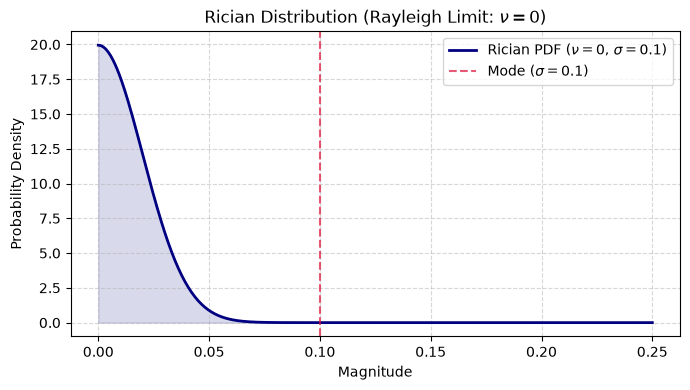

Starting Monte Carlo with 1000 simulations: 100%|██████████| 1000/1000 [00:04<00:00, 203.40it/s]


In [ ]:
from microtool.monte_carlo.simulation import MonteCarloSimulation
from scipy import stats
import matplotlib.pyplot as plt

ball_model["model_D"].value = 2

noise_distribution = stats.norm(0, scale=0.02)



# Perform a Monte Carlo simulation using the initial scheme.
simulation = MonteCarloSimulation(
    initial_scheme,
    ball_model,
    noise_distribution,
    n_sim=1000,
    fit_options={"diff_step": 1e-4},
)a
simulation.run()
initial = simulation.result
simulation.save(simdir / "initial.pkl")

# Repeat the simulation using the optimized scheme.
simulation.set_scheme(optimal_scheme_SOMA)
simulation.run()
optimal = simulation.result
simulation.save(simdir / "optimal.pkl")

Valid fits: initial=1000, optimal=1000

Initial scheme
             bias      std     RMSE  scaled bias  scaled std  scaled RMSE
model_D  0.00395  0.12390  0.12396      0.00197     0.06195      0.06198
T2       0.00020  0.00326  0.00327      0.00407     0.06528      0.06541
S0       0.00340  0.07760  0.07768      0.00340     0.07760      0.07768 
TOTAL scaled RMSE: 0.06869

Optimal scheme
             bias      std     RMSE  scaled bias  scaled std  scaled RMSE
model_D  0.00247  0.08473  0.08477      0.00124     0.04237      0.04238
T2       0.00016  0.00252  0.00252      0.00318     0.05039      0.05049
S0       0.00078  0.05109  0.05110      0.00078     0.05109      0.05110 
TOTAL scaled RMSE: 0.04815

Improvement of total scaled RMSE: 29.9%


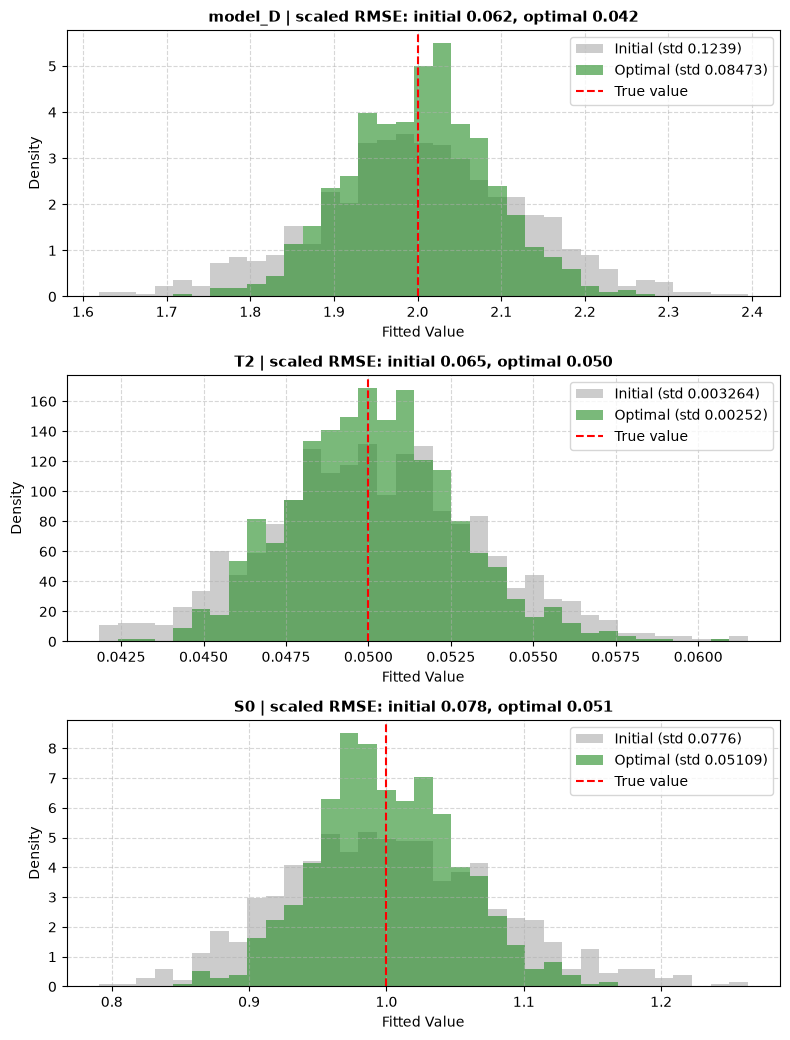

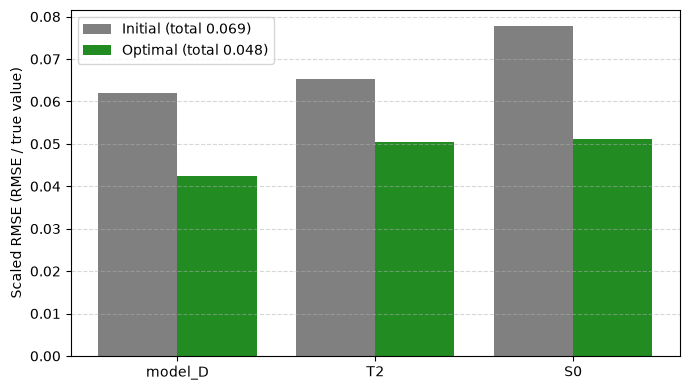

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ data
df_init = pd.DataFrame(initial)
df_opt = pd.DataFrame(optimal)

# ground truth used for the simulation (same units as the fitted columns)
true_values = {
    "model_D": 2,     # 1e-9 m²/s
    "T2":      0.050,   # seconds
    "S0":      1.0,
}
scales = dict(true_values)   # relative RMSE = RMSE / true value

common_cols = [c for c in df_opt.columns if c in df_init.columns and c in true_values]
missing = [c for c in df_opt.columns if c in df_init.columns and c not in true_values]
if missing:
    print(f"Skipping columns without a true value: {missing}")

# drop failed fits (NaN / inf)
df_init = df_init[common_cols].replace([np.inf, -np.inf], np.nan).dropna()
df_opt = df_opt[common_cols].replace([np.inf, -np.inf], np.nan).dropna()
print(f"Valid fits: initial={len(df_init)}, optimal={len(df_opt)}")


# ------------------------------------------------------------------ RMSE
def rmse_table(df):
    rows = {}
    for col in common_cols:
        err = df[col].to_numpy() - true_values[col]
        rmse = np.sqrt(np.mean(err ** 2))
        s = abs(scales[col])
        rows[col] = {
            "bias": err.mean(),
            "std": err.std(),
            "RMSE": rmse,
            "scaled bias": err.mean() / s,
            "scaled std": err.std() / s,
            "scaled RMSE": rmse / s,
        }
    tab = pd.DataFrame(rows).T
    total = np.sqrt(np.mean(tab["scaled RMSE"] ** 2))
    return tab, total


tab_init, total_init = rmse_table(df_init)
tab_opt, total_opt = rmse_table(df_opt)

print("\nInitial scheme\n", tab_init.round(5), f"\nTOTAL scaled RMSE: {total_init:.5f}")
print("\nOptimal scheme\n", tab_opt.round(5), f"\nTOTAL scaled RMSE: {total_opt:.5f}")
print(f"\nImprovement of total scaled RMSE: {100 * (1 - total_opt / total_init):.1f}%")

# ------------------------------------------------------------------ histograms
fig, axes = plt.subplots(
    nrows=len(common_cols), ncols=1, figsize=(8, 3.5 * len(common_cols)), squeeze=False
)

for i, col in enumerate(common_cols):
    ax = axes[i, 0]

    # shared bin edges so both histograms are directly comparable
    both = np.concatenate([df_init[col].to_numpy(), df_opt[col].to_numpy()])
    bins = np.linspace(both.min(), both.max(), 36)

    ax.hist(df_init[col], bins=bins, density=True, alpha=0.4, color="gray",
            label=f"Initial (std {tab_init.loc[col, 'std']:.4g})")
    ax.hist(df_opt[col], bins=bins, density=True, alpha=0.6, color="forestgreen",
            label=f"Optimal (std {tab_opt.loc[col, 'std']:.4g})")
    ax.axvline(true_values[col], color="red", linestyle="--", label="True value")

    ax.set_title(
        f"{col} | scaled RMSE: initial {tab_init.loc[col, 'scaled RMSE']:.3f}, "
        f"optimal {tab_opt.loc[col, 'scaled RMSE']:.3f}",
        fontsize=11, fontweight="bold",
    )
    ax.set_xlabel("Fitted Value")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------ bar plot
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(common_cols))
ax.bar(x - 0.2, tab_init["scaled RMSE"], 0.4, color="gray",
       label=f"Initial (total {total_init:.3f})")
ax.bar(x + 0.2, tab_opt["scaled RMSE"], 0.4, color="forestgreen",
       label=f"Optimal (total {total_opt:.3f})")
ax.set_xticks(x)
ax.set_xticklabels(common_cols)
ax.set_ylabel("Scaled RMSE (RMSE / true value)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5, axis="y")
plt.tight_layout()
plt.show()